In [1]:
# Cell 1 — Imports + notebook settings
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional (recommended): env validity checks
try:
    from gymnasium.utils.env_checker import check_env
    HAVE_CHECK_ENV = True
except Exception:
    HAVE_CHECK_ENV = False

plt.rcParams["figure.figsize"] = (10, 5)

from som_rl.som.som_backend import SOMBackendConfig, SOMControl
from som_rl.env.env import SOMEnvConfig, SOMBinningEnv


In [2]:
# Cell 2 — Paths + constants (edit ROOT if needed)
ROOT = "data"  # change if your notebook lives elsewhere

NPZ_PATH = os.path.join(ROOT, "correlations_dl", "npairs_compact.npz")
NODE_INDICES_PATH = os.path.join(ROOT, "node_indices_fc.npy")
INIT_NODE_BINS_PATH = os.path.join(ROOT, "nodes_labels_initial_fc_200_ext.npy")
REF_LABELS_PATH = os.path.join(ROOT, "reference_labels_fc_fc.npy")  # you said this is the path

# Optional for visuals only (no RL): U-matrix if you have it
UMATRIX_PATH = os.path.join(ROOT, "umatrix_fc_200.npy")  # if not present, leave as-is

H, W = 200, 200
K = 11
N_NODES = H * W


In [3]:
# Cell 3 — Load backend inputs + basic shape checks
npz = np.load(NPZ_PATH)
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

# Drop last dimension for compatibility
dd = dd.squeeze(-1)
dr = dr.squeeze(-1)
rd = rd.squeeze(-1)
rr = rr.squeeze(-1)

node_indices_photo = np.load(NODE_INDICES_PATH)
initial_node_bins = np.load(INIT_NODE_BINS_PATH).astype(np.int32)
reference_labels = np.load(REF_LABELS_PATH).astype(np.int32)

umatrix = None
if os.path.exists(UMATRIX_PATH):
    umatrix = np.load(UMATRIX_PATH).astype(np.float32)

print("dd/dr/rd/rr:", dd.shape, dr.shape, rd.shape, rr.shape)
print("node_indices_photo:", node_indices_photo.shape, node_indices_photo.dtype)
print("initial_node_bins:", initial_node_bins.shape, initial_node_bins.dtype, "min/max:", initial_node_bins.min(), initial_node_bins.max())
print("reference_labels:", reference_labels.shape, reference_labels.dtype, "min/max:", reference_labels.min(), reference_labels.max())

assert initial_node_bins.shape == (N_NODES,)
assert reference_labels.ndim == 1
assert node_indices_photo.ndim == 1


dd/dr/rd/rr: (11, 40000) (11, 40000) (11, 40000) (11, 40000)
node_indices_photo: (72273925,) int64
initial_node_bins: (40000,) int32 min/max: 0 10
reference_labels: (8030436,) int32 min/max: 0 10


In [4]:
# Cell 4 — Instantiate SOMControl backend
# Assumes you have SOMBackendConfig + SOMControl defined in your project (import or paste above).
# If it's in a module, do: from som_backend import SOMBackendConfig, SOMControl

cfg_backend = SOMBackendConfig(grid_shape=(H, W), num_bins=K)

som = SOMControl(
    cfg=cfg_backend,
    dd=dd, dr=dr, rd=rd, rr=rr,
    node_indices_photo=node_indices_photo,
    initial_node_bins=initial_node_bins,
    reference_labels=reference_labels,
    umatrix=umatrix,
)

print("Backend OK:", "H,W,N,K =", som.H, som.W, som.N, som.K)
print("Initial reward_trace:", som.reward_trace())
print("Eligible nodes (gal>0):", int(np.sum(som.node_gal_counts > 0)), "/", som.N)


Backend OK: H,W,N,K = 200 200 40000 11
Initial reward_trace: 0.2785188710136125
Eligible nodes (gal>0): 40000 / 40000


In [5]:
# Cell 5 — Quick backend sanity: step a few eligible nodes, ensure caches consistent and reward changes
rng = np.random.default_rng(0)
eligible_nodes = np.flatnonzero(som.node_gal_counts > 0)

r0 = som.reward_trace()
print("r0:", r0)

for t in range(5):
    node = int(rng.choice(eligible_nodes))
    out = som.step_node(node)
    print(t, out)

r1 = som.reward_trace()
print("r1:", r1)
print("delta:", r1 - r0)

# Minimal invariants
assert som.current_bins.shape == (som.N,)
assert np.all((som.current_bins >= 0) & (som.current_bins < som.K))


r0: 0.2785188710136125
0 {'node': 34024, 'old_bin': 7, 'chosen_bin': 7, 'best_delta': 0.0, 'is_noop': True, 'delta_reward': 0.0, 'reward': 0.2785188710136125}
1 {'node': 25478, 'old_bin': 6, 'chosen_bin': 9, 'best_delta': 0.000810563978240253, 'is_noop': False, 'delta_reward': 0.000810563978240253, 'reward': 0.27932943499185275}
2 {'node': 20445, 'old_bin': 6, 'chosen_bin': 10, 'best_delta': 1.863653538902721e-05, 'is_noop': False, 'delta_reward': 1.863653538902721e-05, 'reward': 0.2793480715272418}
3 {'node': 10791, 'old_bin': 2, 'chosen_bin': 0, 'best_delta': 4.589330231952182e-07, 'is_noop': False, 'delta_reward': 4.589330231952182e-07, 'reward': 0.279348530460265}
4 {'node': 12313, 'old_bin': 5, 'chosen_bin': 5, 'best_delta': 0.0, 'is_noop': True, 'delta_reward': 0.0, 'reward': 0.279348530460265}
r1: 0.279348530460265
delta: 0.0008296594466524754


In [6]:
# Cell 6 — Construct Env + check spaces
# Assumes SOMEnvConfig + SOMBinningEnv are defined (import or paste).
cfg_env = SOMEnvConfig(
    grid_shape=(H, W),
    torus=True,
    action_mode="teleport_node",
    obs_mode="local_patch",
    patch_size=9,
    allow_act_every_step=True,
    reward_type="delta",
    max_steps=200,
    include_umatrix=(umatrix is not None),
    include_visit_count=True,
    include_cooldown=True,
    include_steps_since_act=True,
    cooldown_steps=5,
    cooldown_policy="no_act",
)

env = SOMBinningEnv(som_control=som, cfg=cfg_env)

print("action_space:", env.action_space)
print("observation_space:", env.observation_space)

if HAVE_CHECK_ENV:
    # This can be slow-ish but is worth running once.
    check_env(env, skip_render_check=True)
    print("check_env: PASSED")
else:
    print("gymnasium env_checker not available; skipped.")


action_space: Discrete(40000)
observation_space: Dict('bins': Box(0, 10, (9, 9), int32), 'cooldown': Box(0, 5, (9, 9), int32), 'cursor': Box(0, 200, (2,), int32), 'steps_since_act': Box(0, 10000, (9, 9), int32), 'visit_count': Box(0, 2147483647, (9, 9), int32))
check_env: PASSED


In [7]:
# Cell 7 — Reset + inspect observation dict keys/shapes/dtypes
obs, info = env.reset(seed=123)
print("reset info:", info)

for k, v in obs.items():
    if isinstance(v, np.ndarray):
        print(f"{k:>15} shape={v.shape} dtype={v.dtype} min={v.min()} max={v.max()}")
    else:
        print(f"{k:>15} type={type(v)}")

# basic checks
assert "bins" in obs and "cursor" in obs
assert obs["bins"].dtype == np.int32
assert obs["bins"].min() >= 0 and obs["bins"].max() <= 10


reset info: {'reward': 0.2785188710136125}
         cursor shape=(2,) dtype=int32 min=3 max=136
           bins shape=(9, 9) dtype=int32 min=0 max=10
    visit_count shape=(9, 9) dtype=int32 min=0 max=0
       cooldown shape=(9, 9) dtype=int32 min=0 max=0
steps_since_act shape=(9, 9) dtype=int32 min=10000 max=10000


In [8]:
# Cell 8 — Rollout smoke test: random valid actions, record rewards + noop + cooldown blocks
rng = np.random.default_rng(42)

T = 200
rewards = np.zeros(T, dtype=np.float64)
deltas = np.zeros(T, dtype=np.float64)
is_noop = np.zeros(T, dtype=bool)
cooldown_blocked = np.zeros(T, dtype=bool)

# for teleport_node, sample eligible nodes to avoid lots of dead nodes
eligible_nodes = np.flatnonzero(env.som.node_gal_counts > 0)

obs, info = env.reset(seed=0)
for t in range(T):
    a = int(rng.choice(eligible_nodes))
    obs, r, terminated, truncated, info = env.step(a)
    rewards[t] = r
    deltas[t] = float(info.get("delta_reward", 0.0))
    is_noop[t] = bool(info.get("is_noop", False))
    cooldown_blocked[t] = bool(info.get("cooldown_blocked", False))

    if terminated or truncated:
        print("ended at t=", t, "terminated=", terminated, "truncated=", truncated, "reason=", info.get("terminated_reason"))
        break

print("mean reward:", rewards.mean(), "std:", rewards.std())
print("noop rate:", is_noop.mean())
print("cooldown blocked rate:", cooldown_blocked.mean())


ended at t= 199 terminated= False truncated= True reason= None
mean reward: 1.2700048295294086e-05 std: 4.8289839038752374e-05
noop rate: 0.485
cooldown blocked rate: 0.0


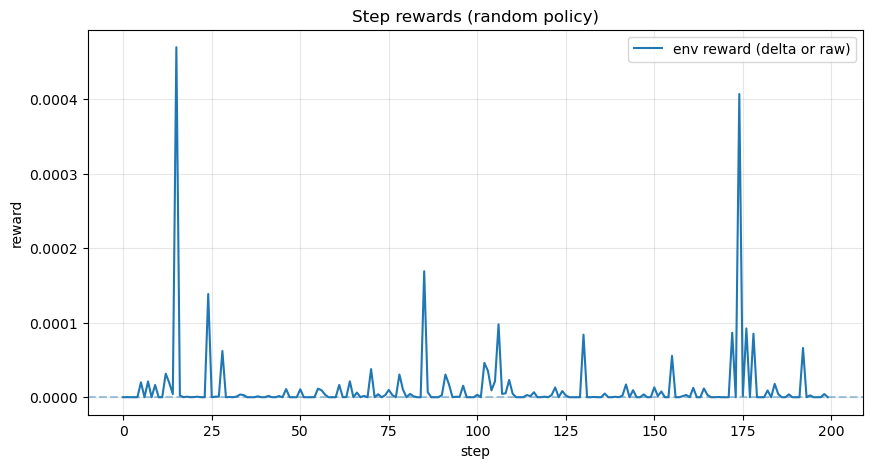

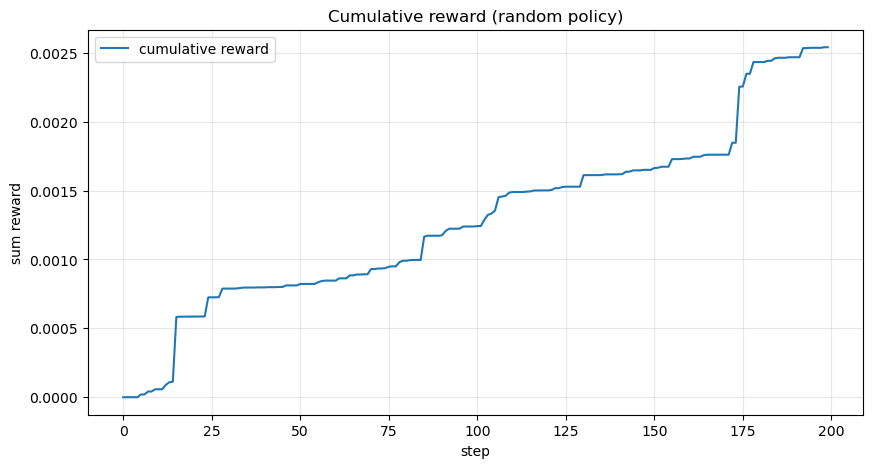

In [9]:
# Cell 9 — Plot reward trace and cumulative reward
plt.figure()
plt.plot(rewards, label="env reward (delta or raw)")
plt.axhline(0, linestyle="--", alpha=0.4)
plt.title("Step rewards (random policy)")
plt.xlabel("step")
plt.ylabel("reward")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure()
plt.plot(np.cumsum(rewards), label="cumulative reward")
plt.title("Cumulative reward (random policy)")
plt.xlabel("step")
plt.ylabel("sum reward")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [10]:
# Cell 10 — Verify env+backend reward consistency:
# If env.reward_type=="delta", then reward should match backend reward change (modulo noop_penalty/clipping).
env.reset(seed=1)
r_prev = env.som.reward_trace()
ok = 0
bad = 0

for t in range(50):
    node = int(np.random.choice(np.flatnonzero(env.som.node_gal_counts > 0)))
    obs, r, term, trunc, info = env.step(node)

    r_now = env.som.reward_trace()
    delta_true = r_now - r_prev
    r_prev = r_now

    if info.get("acted", False) and not info.get("cooldown_blocked", False):
        # if clipping is on, don't compare strictly
        if env.cfg.clip_reward is None and env.cfg.no_op_penalty == 0.0:
            if abs(delta_true - r) < 1e-9:
                ok += 1
            else:
                bad += 1
    if term or trunc:
        break

print("delta-match ok:", ok, "bad:", bad)


delta-match ok: 50 bad: 0


blocked: [False, True, True, True, True, False, True, True, True, True, False, True, True, True, True, False, True, True, True, True]
acted:   [True, False, False, False, False, True, False, False, False, False, True, False, False, False, False, True, False, False, False, False]
cooldown(center): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


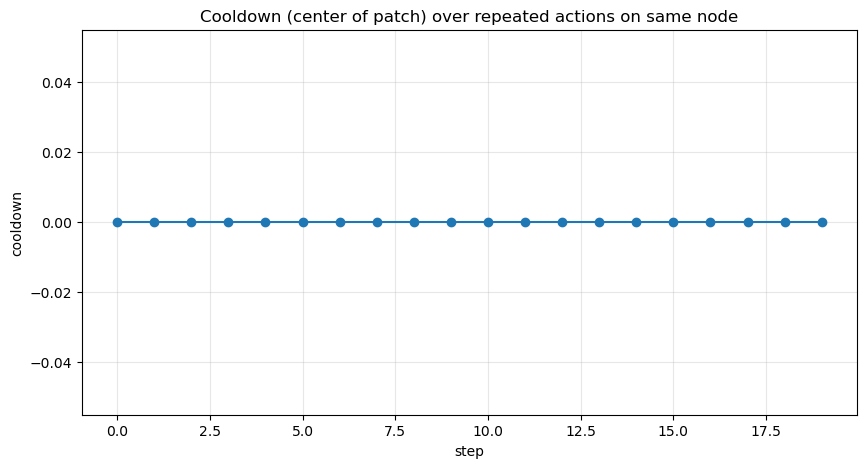

In [11]:
# Cell 11 — Cooldown channel sanity:
# Pick one node repeatedly; confirm it gets blocked and cooldown decreases over time.
env.reset(seed=7)

eligible_nodes = np.flatnonzero(env.som.node_gal_counts > 0)
node = int(eligible_nodes[0])

cool_vals = []
acted_vals = []
blocked_vals = []

for t in range(20):
    obs, r, term, trunc, info = env.step(node)
    blocked = bool(info.get("cooldown_blocked", False))
    acted = bool(info.get("acted", False))
    blocked_vals.append(blocked)
    acted_vals.append(acted)

    # Read cooldown at cursor patch center (only if local_patch and cooldown enabled)
    if "cooldown" in obs:
        c = int(obs["cooldown"][env.r, env.r])  # center of patch
        cool_vals.append(c)

print("blocked:", blocked_vals)
print("acted:  ", acted_vals)
print("cooldown(center):", cool_vals)

plt.figure()
plt.plot(cool_vals, marker="o")
plt.title("Cooldown (center of patch) over repeated actions on same node")
plt.xlabel("step")
plt.ylabel("cooldown")
plt.grid(True, alpha=0.3)
plt.show()


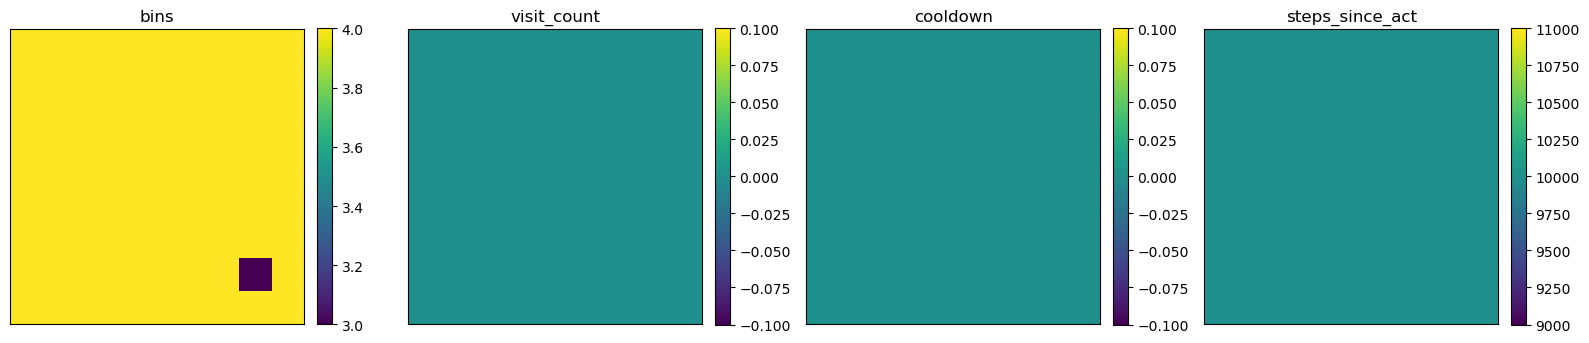

In [12]:
# Cell 12 — Observation channels visualization (bins + visit_count + cooldown + steps_since_act)
obs, info = env.reset(seed=9)

def show_channels(obs_dict):
    keys = ["bins"]
    for k in ["visit_count", "cooldown", "steps_since_act", "umatrix"]:
        if k in obs_dict:
            keys.append(k)

    n = len(keys)
    fig, axs = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1:
        axs = [axs]

    for ax, k in zip(axs, keys):
        im = ax.imshow(obs_dict[k])
        ax.set_title(k)
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

show_channels(obs)


In [13]:
# Cell 13 — Speed micro-benchmarks: backend step_node vs env.step (teleport_node)
# This catches integration overhead, and confirms you can do large action counts.
eligible_nodes = np.flatnonzero(env.som.node_gal_counts > 0)
rng = np.random.default_rng(123)

N_STEPS = 5000
nodes = rng.choice(eligible_nodes, size=N_STEPS, replace=True).astype(np.int64)

# --- backend-only timing (no env overhead)
som.reset_to_initial()
t0 = time.time()
for n in nodes:
    som.step_node(int(n))
t_backend = time.time() - t0

# --- env timing
env.reset(seed=0)
t0 = time.time()
for n in nodes:
    env.step(int(n))
t_env = time.time() - t0

print(f"Backend: {N_STEPS} step_node in {t_backend:.3f}s  | {N_STEPS/t_backend:.1f} steps/s")
print(f"Env:     {N_STEPS} env.step   in {t_env:.3f}s  | {N_STEPS/t_env:.1f} steps/s")
print(f"Env overhead factor: {t_env / (t_backend + 1e-12):.2f}x")


Backend: 5000 step_node in 1.773s  | 2820.1 steps/s
Env:     5000 env.step   in 2.278s  | 2194.7 steps/s
Env overhead factor: 1.28x


samples: 2000
positive-delta fraction: 0.4335
noop fraction: 0.5665
delta mean/std: 7.72590856255917e-06 3.466693583931231e-05


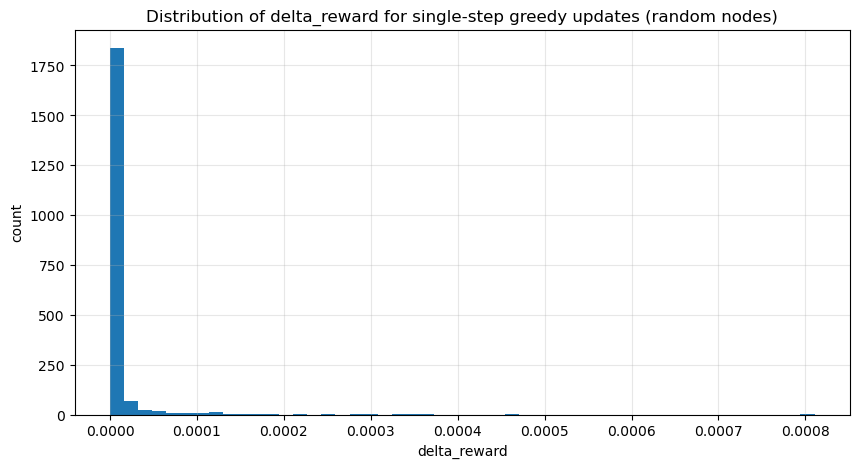

In [14]:
# Cell 14 — Greedy action sanity: env.step should usually choose non-noop on high-potential nodes.
# Quick heuristic: sample many nodes once, measure noop rate and positive delta rate.
env.reset(seed=0)
eligible_nodes = np.flatnonzero(env.som.node_gal_counts > 0)
rng = np.random.default_rng(0)

M = 2000
pos = 0
noop = 0
deltas = []

for _ in range(M):
    n = int(rng.choice(eligible_nodes))
    obs, r, term, trunc, info = env.step(n)
    d = float(info.get("delta_reward", 0.0))
    deltas.append(d)
    if bool(info.get("is_noop", False)):
        noop += 1
    if d > 0:
        pos += 1

deltas = np.array(deltas)
print("samples:", M)
print("positive-delta fraction:", pos / M)
print("noop fraction:", noop / M)
print("delta mean/std:", deltas.mean(), deltas.std())

plt.figure()
plt.hist(deltas, bins=50)
plt.title("Distribution of delta_reward for single-step greedy updates (random nodes)")
plt.xlabel("delta_reward")
plt.ylabel("count")
plt.grid(True, alpha=0.3)
plt.show()
